In [1]:
# In this notebook we plot the output from Code 

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import plot_utils as pltutils

In [2]:
def read_SEDsyn_cuts(filename='./../Code/SEDsyn_cuts_ord.dat'):
    fname = filename
    #fname format: Esy, Lsy*Esy, Labssy, l
    data = np.loadtxt(fname).transpose()
    Ns = int( np.max(data[3]) )
    NSED_sy = np.size(data[3]) // Ns
    print(f'{Ns=}, {NSED_sy=}')
    
    Esy = data[0][:NSED_sy]
    Lsy = np.zeros((Ns, NSED_sy))
    for i in range(Ns):
        Lsy[i] = data[2][i*NSED_sy:(i+1)*NSED_sy] / data[0][:NSED_sy]
    
    return Esy, Lsy, Ns, NSED_sy

In [3]:
eV = 1.60218e-12
pc = 3.086e+18

# Read zmin and zmax from the trajectory
traj = np.loadtxt('./../Code/trajectory.dat')
zmin = np.min(traj[:,0])
zmax = np.max(traj[:,0])

# Read the synchrotron SED at each cut (segment) along the jet; file already sorted in Esy
# Ns and NSED are the number of segments and of energy points, respectively
Esy, Lsy, Ns, NSED = read_SEDsyn_cuts()

# Read a file containing E, L1, L2, ..., Ltot (L1, ... are integrated up to certain heights)
synsed_output = np.loadtxt('./../Code/SEDsyn_jet.dat')
Lsy_tot_abs = synsed_output[:,-1]
Lsy_tot_unabs = synsed_output[:,-2]

Ns=100, NSED_sy=150


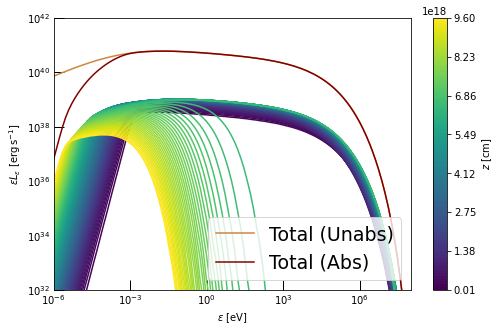

In [4]:
# Init plot
fig, ax= plt.subplots(1,1, figsize=(8,5))
colors = pltutils.iar_aut

# Plot total SED
ax.loglog(Esy, Lsy_tot_unabs, label='Total (Unabs)', color=colors[0])
ax.loglog(Esy, Lsy_tot_abs, label='Total (Abs)', color=colors[1])

# Plot individual curves for different Z

colormap, sm = pltutils.color_from_cmap('viridis',Ns, vmin=int(zmin), vmax=int(zmax))
for i in range(Ns):
    ax.loglog(Esy,Esy*Lsy[i], color=colormap[i])

plt.colorbar(sm, ticks=np.linspace(zmin, zmax, 8), label='$z ~ [\mathrm{cm}]$')
# Set limits#
ax.set_ylim([1e32,1e42])
ax.set_xlim([1e-6,1e8])

# Legends and labels
plt.legend(loc='lower right', fontsize=19)
ax.set_xlabel('$\epsilon ~ [\mathrm{eV}]$')
ax.set_ylabel('$\epsilon L_{\epsilon} ~ [\mathrm{erg\,s^{-1}}]$')

# Set the style of the plot
pltutils.luc_std_plot(ax)
pltutils.luc_std_plot(ax)

plt.show()



/tmp/ipykernel_28468/4023026926.py:33: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  plt.colorbar(sm, ticks=z_ticks, label='$z/z_0$')


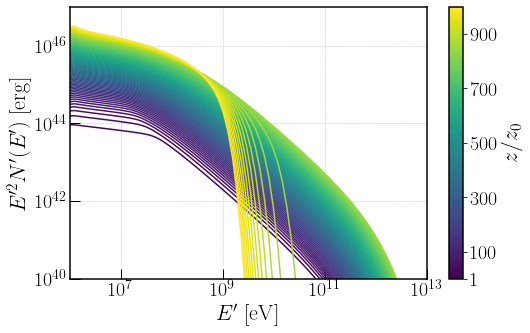

In [5]:
# # N(E) distribution

# Read the output of the jet model
NE_output_ord = np.loadtxt('./../Code/NE_cuts_ord.dat')

# Define quantities for N cuts
Eecut = NE_output_ord[:,0]
necut = NE_output_ord[:,1]

# take dimensions from array
n = int( np.max(NE_output_ord[:,2]) )
m = int( len(NE_output_ord[:,2]) / n )
# reshape arrays
Eecut = np.reshape(Eecut,(n,m))
necut = np.reshape(necut,(n,m))

# Init plot
fig, ax= plt.subplots(1,1, figsize=(8,5))
colors = pltutils.iar_aut

# Plot individual curves for different z
colormap, sm = pltutils.color_from_cmap('viridis', m, vmin=1.0, vmax=zmax/zmin)
#colormap, sm = pltutils.color_from_cmap('viridis', m, vmin=zmin, vmax=zmax)
for i in range(m):
    ax.loglog(Eecut[i]/eV,necut[i]*Eecut[i]**2, color=colormap[i])

#z_ticks = np.linspace(0, zmax, 8)
#z_ticks2 = [float('{:.2g}'.format(z)) for z in z_ticks]
#plt.colorbar(sm, ticks=z_ticks2, label='$z(\\rm cm)$')

#z_ticks = np.linspace(1.0, zmax/zmin, 8)
z_ticks = [1.0, 100, 300, 500, 700, 900]
plt.colorbar(sm, ticks=z_ticks, label='$z/z_0$')

# Set limits#
ax.set_ylim([1e40,1e47])
ax.set_xlim([1e6,1e13])

# Legends and labels
#plt.legend(loc='upper right', fontsize=19)
ax.set_xlabel('$E\' \; [\mathrm{eV}]$')
ax.set_ylabel('$E\'^2 N\' (E\') \; [\mathrm{erg}]$')

# Set the style of the plot
pltutils.luc_std_plot(ax)
plt.show()

fig.savefig('NE_cuts.pdf', bbox_inches='tight', pad_inches = 0)

/tmp/ipykernel_28468/3826881225.py:50: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cbar = fig.colorbar(sm, ticks=c_ticks, label=r"bin", pad=0.02)


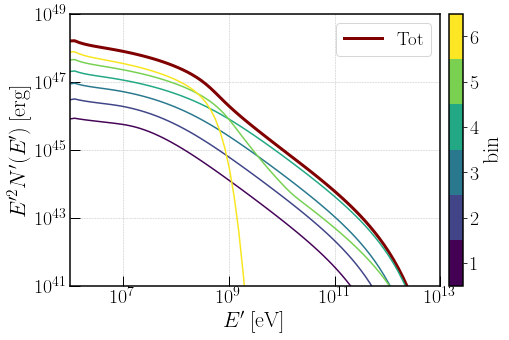

In [6]:
# # N(E) distribution

# Read the output of the jet model
data_NE_tot = np.loadtxt('./../Code/Ne_total.dat')
data_NE_bin = np.loadtxt('./../Code/Ne_bin.dat')

# Define quantities for total N
Ee_tot = data_NE_tot[:,0] 
NE_tot = data_NE_tot[:,1]

# Define quantities for N bins 
NE_bin = data_NE_bin[:,2]

# take dimensions from array
n_bins = int( np.max(data_NE_bin[:,0]) )
m = int( len(data_NE_bin[:,2]) / n_bins )
# reshape arrays
NE_bin = np.reshape(NE_bin,(n_bins,m))

# Define a discrete palette for "n_bins" colors
color_vector = np.linspace(0.01,0.99,n_bins)
color_pal = plt.cm.viridis(color_vector) # define a palette avoiding extreme colors
c_ticks = np.arange(1, n_bins+1) 
cmap = plt.cm.get_cmap('viridis', n_bins)
norm = matplotlib.colors.BoundaryNorm(np.arange(n_bins+1)+0.5,n_bins)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Other colours
colors = pltutils.iar_aut

# Init plot
fig, ax= plt.subplots(1,1, figsize=(8,5))

# Plot total SED
ax.loglog(Ee_tot, NE_tot*(Ee_tot*eV)**2, label='Tot', color=colors[1], linewidth=3)

# Plot individual curves for different z
for i in range(n_bins):
    ax.loglog(Ee_tot,NE_bin[i]*(Ee_tot*eV)**2, color=color_pal[i])

# Set limits#
ax.set_ylim([1e41,1e49])
ax.set_xlim([1e6,1e13])

# Legends and labels
plt.legend(loc='upper right', fontsize=19)
ax.set_xlabel('$E\' \: [\\rm eV]$')
ax.set_ylabel('$E\'^2 N \' (E\') \: [\\rm erg]$')

cbar = fig.colorbar(sm, ticks=c_ticks, label=r"bin", pad=0.02)

# Set the style of the plot
pltutils.luc_std_plot(ax)
plt.show()

fig.savefig('NE_bin.pdf', bbox_inches='tight', pad_inches = 0)